In [1]:
# Notebooks live in Notebooks/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("cwd:", os.getcwd())

cwd: /home/lotan.amit/WhatDoLLMsWant


# Synthetic cars — weights, company lines, adherence, goodness of fit (2026-11-18)

The figures we made for the synthetic laptops (`baseline_weights_big3`, `contract_weights_big3`, `figs4deck5_big3`),
redone on the synthetic cars (`data/synthetic_cars/`: 120 cars x 6 features, 28 contracts), for qwen-72B, gemma-27B,
olmo-32B (the only models run on them). The real laptops were here too until 2026-11-18 (progress 11-18 (3)).

| part | what | like |
|---|---|---|
| 1 | learned BT weights, one figure per contract (no contract first) | `baseline_weights_big3`, `contract_weights_big3` |
| 2 | one line per company weight across a contract sequence | Fig 6.2 of `figs4deck5_big3` (Apple's decay) |
| 3 | adherence: Δp on the conflict pairs, every contract | Fig 5.5 D of `figs4deck5_big3` |
| 4 | goodness of fit, summary table | read from `scripts/goodness_of_fit.py` |

**Choices made here**

- **Which pairs a fit uses.** No contract and the single contracts: all 7,140 pairs. A compound run also holds every
  pair with one of its track's target cars; those rows bias an additive fit (progress 2026-11-15), so a compound run
  is fitted on the **500 shared pairs** only.
- **Part 2 fits every point of a line on the same 500 pairs** (the compound pairs), so the only thing that changes
  along a line is the contract. Its "no contract" point is therefore not exactly the bar of part 1.
- **Part 3 — which pairs.** The model's own preference is read pair by pair from the **no-contract run**. For a
  contract: the pairs where exactly one item meets it; a pair is a **conflict** pair when that item *loses* with no
  contract (position-corrected margin D < 0) — obeying costs. Δp is measured on those pairs, under the contract.
  Same definition as F11r of `real_laptops_trends`. A conflict pair can differ in more than the asked feature.
- PMI is off in all these runs (max score 0), so no offset C is needed.

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from src.bt import FeatureBT

pd.set_option("display.width", 220)
FIGDIR = "figs/synthetic_cars_big3"
os.makedirs(FIGDIR, exist_ok=True)

MODELS = [("qwen", "72"), ("gemma", "27"), ("olmo", "32")]
def name(m): return f"{m[0]}-{m[1]}B"

SURFACE, INK, INK_MUTED = "#fcfcfb", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": "#d6d5d1", "axes.labelcolor": INK, "axes.titlecolor": INK,
    "text.color": INK, "xtick.color": INK_MUTED, "ytick.color": INK_MUTED,
    "axes.grid": True, "grid.color": "#e8e7e3", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110,
    "font.size": 10, "savefig.bbox": "tight", "savefig.dpi": 200,
})


def save(fig, sub, fname, dpi=None):
    os.makedirs(os.path.join(FIGDIR, sub), exist_ok=True)
    fig.savefig(os.path.join(FIGDIR, sub, fname + ".png"), facecolor=SURFACE, dpi=dpi)
    fig.savefig(os.path.join(FIGDIR, sub, fname + ".pdf"), facecolor=SURFACE)


OWN ={"private first owner": "1st owner", "private second owner": "2nd owner", "private third owner": "3rd owner"}
DS = {
    "cars": dict(
        title="synthetic cars", base="data/synthetic_cars", frame="car_shopping", company="company",
        feats=["company", "color", "fuel", "transmission", "ownership", "horsepower"],
        levels={"company": ["Honda", "Toyota", "Ford", "BMW", "Audi", "Mercedes"],
                "color": ["white", "black", "silver", "red", "blue", "grey"], "fuel": ["petrol", "diesel"],
                "transmission": ["manual", "automatic"],
                "ownership": ["private first owner", "private second owner", "private third owner", "ex-lease", "ex-rental"],
                "horsepower": ["100 hp", "150 hp", "200 hp"]},
        feat_label={"company": "company", "color": "color", "fuel": "fuel", "transmission": "trans.",
                    "ownership": "owner", "horsepower": "hp"},
        feat_color=dict(zip(["company", "color", "fuel", "transmission", "ownership", "horsepower"],
                            ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"])),   # as synthetic_cars_trends
        level_label=lambda l: OWN.get(l, l),
        raw_label=lambda l: OWN.get(l, l)),
}
for k, D in DS.items():
    D["items"] = pd.read_csv(f"{D['base']}/design/items.csv").set_index("id")
    D["cids"] = list(pd.read_csv(f"{D['base']}/design/contracts.csv").constraints_id)       # design order
    P = pd.read_csv(f"{D['base']}/design/compound_pairs.csv").values
    D["shared"] = set(map(tuple, P)) | set(map(tuple, P[:, ::-1]))                         # the 500 pairs, both orders
    D["LV"] = [(f, l) for f in D["feats"] for l in D["levels"][f]]
    D["ids"] = list(D["items"].index)
    D["pos"] = {i: k for k, i in enumerate(D["ids"])}


def parse(cid):
    return dict(p.split("=") for p in cid.split("+")) if cid != "none" else {}


def short(ds, cid):
    """'BMW + automatic + 200 hp' - the asked levels in feature order."""
    con, D = parse(cid), DS[ds]
    return " + ".join(D["raw_label"](con[f]) for f in D["feats"] if f in con) or "no contract"

## Load the runs

In [3]:
RUNS = {"cars": {}}      # ds -> (model, constraints_id) -> scores
for ds, D in DS.items():
    for r in sorted(os.listdir(D["base"])):
        cf, sc = f"{D['base']}/{r}/config.json", f"{D['base']}/{r}/scores.csv"
        if not (os.path.isfile(cf) and os.path.isfile(sc)):
            continue                                       # log-only folder, or config without scores = dead run
        c = json.load(open(cf))
        d = pd.read_csv(sc)
        m = (c["model_family"], str(c["model_size"]))
        if m not in MODELS or c["frame"]["name"] != D["frame"] or len(d) != c["n_rows"]:
            continue
        key = (m, c["constraints_id"])
        assert key not in RUNS[ds], f"two complete runs share {key}"
        assert max(d.score_a.max(), d.score_b.max()) < 1e-3, "PMI looks on"
        RUNS[ds][key] = d
    assert len(RUNS[ds]) == len(MODELS) * len(D["cids"]), (ds, len(RUNS[ds]))
    print(f"{D['title']}: {len(RUNS[ds])} runs = {len(MODELS)} models x {len(D['cids'])} contracts")


def fit_frame(ds, d, shared=False):
    """scores.csv with only the named features; FeatureBT fits every a_* column, so a_id must go."""
    D = DS[ds]
    if shared:
        d = d[[k in D["shared"] for k in zip(d.a_id, d.b_id)]]
    out = pd.DataFrame({"score_a": d.score_a.values, "score_b": d.score_b.values})
    for s in "ab":
        for f in D["feats"]:
            out[f"{s}_{f}"] = d[f"{s}_{f}"].values
    return out


def fit(ds, m, cid, shared=False):
    return FeatureBT(r2_warn=None).fit(fit_frame(ds, RUNS[ds][(m, cid)], shared))


def weights(ds, bt):
    return pd.Series({(f, l): bt.weights_[f].get(l, np.nan) for f, l in DS[ds]["LV"]})

synthetic cars: 84 runs = 3 models x 28 contracts


---
# Part 1 — the learned weights, one figure per contract

Same figure as `baseline_weights_big3`: one panel per model, each with **its own y-axis** (the size of the weights is
not comparable between models, only the shape). Weights are centred inside each feature. The level(s) a contract asks
for are **bold** on the x-axis.

In [4]:
W, INFO = {"cars": {}}, []
for ds, D in DS.items():
    for cid in D["cids"]:
        shared = "+" in cid                            # compound run: the 500 shared pairs only
        for m in MODELS:
            bt = fit(ds, m, cid, shared)
            W[ds][(cid, m)] = weights(ds, bt)
            INFO.append(dict(dataset=D["title"], contract=cid, model=name(m), pairs="500 shared" if shared else "all in run",
                             rows=bt.n_obs_, R2=bt.r2_, **{f"range {f}": bt.range(f) for f in D["feats"]}))
    pd.DataFrame(W[ds]).rename(columns=lambda c: c, level=1).to_csv(os.path.join(FIGDIR, f"weights_{ds}.csv"))
INFO = pd.DataFrame(INFO)
display(INFO.groupby(["dataset", "model"])[["rows", "R2"]].agg(["min", "median", "max"]).round(2))

rows                    R2             
                           min   median    max   min median   max
dataset        model                                             
synthetic cars gemma-27B  1000  14280.0  14280  0.64   0.74  0.83
               olmo-32B   1000  14280.0  14280  0.74   0.88  0.96
               qwen-72B   1000  14280.0  14280  0.81   0.88  0.92

In [5]:
def nice_tick(v):
    """Biggest round number that is not above v."""
    return max([t for t in [0.1, 0.2, 0.5, 1, 2, 4, 5, 10, 15, 20, 30] if t <= v] or [v])


def fig_weights(ds, cid):
    D, LV = DS[ds], DS[ds]["LV"]
    asked = set(parse(cid).items())
    nb = len(LV)
    with plt.rc_context({"axes.grid": False}):
        fig, axes = plt.subplots(len(MODELS), 1, figsize=(2 * nb / 11, 0.875 * len(MODELS)), sharex=True)
        x = np.arange(nb)
        for ax, m in zip(axes, MODELS):
            w = W[ds][(cid, m)].values
            top = np.nanmax(np.abs(w))
            ax.bar(x, w, 0.78, color=[D["feat_color"][f] for f, _ in LV], zorder=2)
            ax.axhline(0, color="#8d8b85", lw=0.7, zorder=3)
            ax.set_title(name(m), loc="left", fontsize=6, fontweight="bold", pad=1.5)
            ax.set_ylabel("BT weight", fontsize=5, labelpad=1)
            ax.set_ylim(-1.1 * top, 1.1 * top)                 # own scale per model
            t = nice_tick(top)
            ax.set_yticks([-t, 0, t])
            ax.tick_params(axis="y", labelsize=4.5, length=1.5, width=0.4, pad=1, colors=INK_MUTED)
            ax.tick_params(axis="x", length=0, pad=1)
            ax.spines["left"].set_linewidth(0.4)
            ax.spines["bottom"].set_linewidth(0.4)
            ax.set_xlim(-0.6, nb - 0.4)
        axes[0].text(1, 1.02, "no contract" if cid == "none" else f"contract: {short(ds, cid)}",
                     transform=axes[0].transAxes, ha="right", va="bottom", fontsize=5, color=INK_MUTED)
        axes[-1].set_xticks(x, [D["level_label"](l) for _, l in LV], rotation=90, fontsize=4.5, color=INK_MUTED)
        for tick, fl in zip(axes[-1].get_xticklabels(), LV):
            if fl in asked:
                tick.set_fontweight("bold")
                tick.set_color(INK)
        fig.tight_layout(h_pad=0.4, pad=0.15, rect=(0, 0.035, 1, 1))
        fig.align_ylabels(axes)
        # the feature names go under the lowest tick label
        fig.canvas.draw()
        rnd, inv = fig.canvas.get_renderer(), axes[-1].transAxes.inverted()
        low = min(inv.transform((0, t.get_window_extent(rnd).y0))[1] for t in axes[-1].get_xticklabels())
        starts = np.cumsum([0] + [len(D["levels"][f]) for f in D["feats"]])
        for k in starts[1:-1]:
            for ax in axes:
                ax.axvline(k - 0.5, color="#c9c8c3", lw=0.5, zorder=1)
            axes[-1].plot([k - 0.5, k - 0.5], [0, low - 0.22], transform=axes[-1].get_xaxis_transform(), color="#c9c8c3",
                          lw=0.5, clip_on=False)
        for f, a, b in zip(D["feats"], starts[:-1], starts[1:] - 1):
            axes[-1].text((a + b) / 2, low - 0.04, D["feat_label"][f], transform=axes[-1].get_xaxis_transform(),
                          ha="center", va="top", fontsize=6, color=D["feat_color"][f])
        save(fig, f"weights_{ds}", cid, dpi=400)
        plt.show()

## The 28 contracts

none


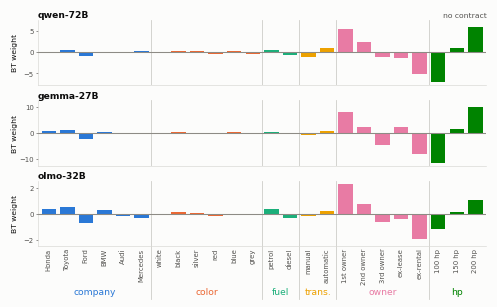

transmission=automatic


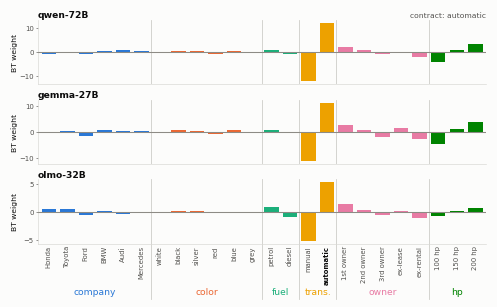

company=BMW


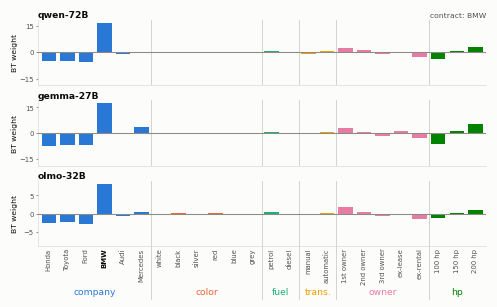

horsepower=200 hp


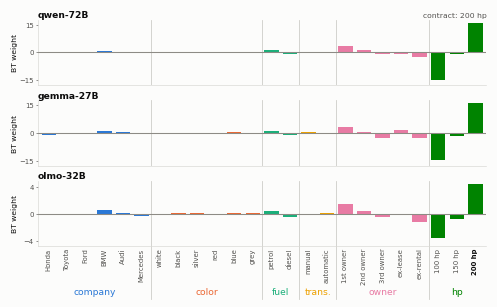

color=black


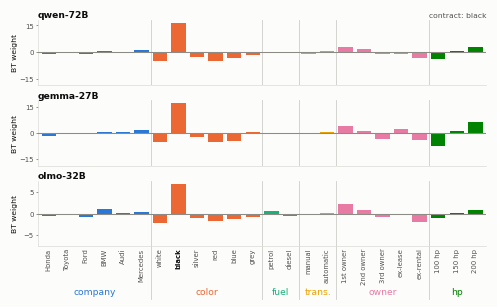

fuel=petrol


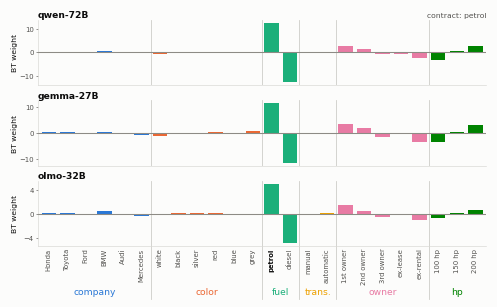

transmission=manual


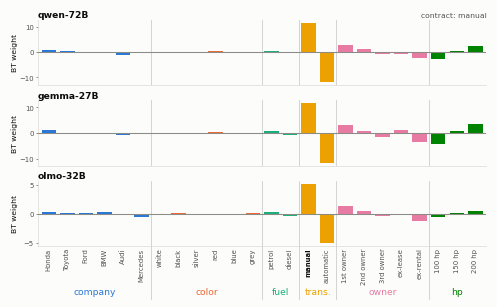

horsepower=100 hp


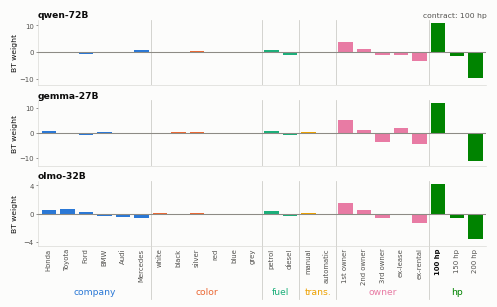

company=Honda


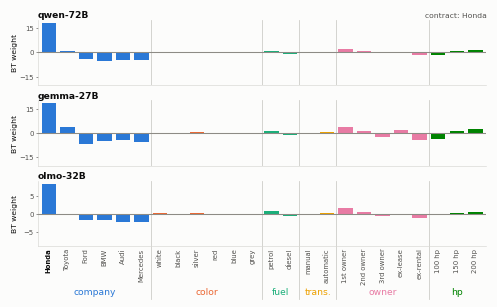

ownership=private first owner


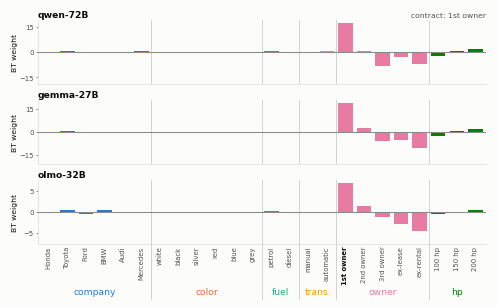

company=Toyota


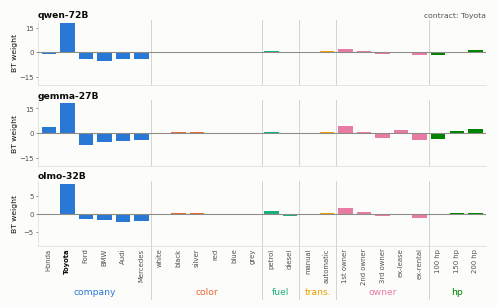

color=white


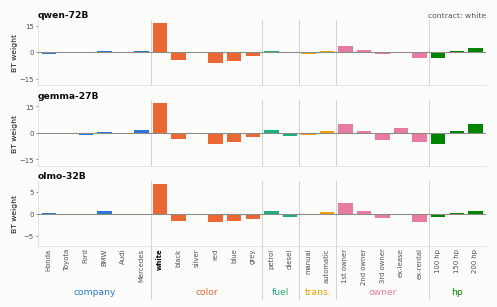

fuel=diesel


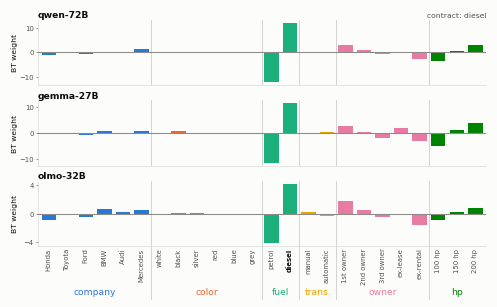

horsepower=150 hp


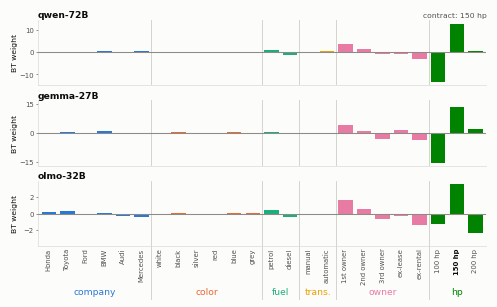

company=Ford


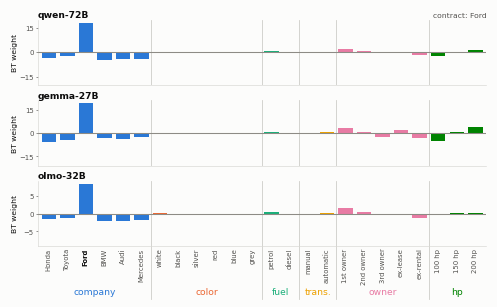

ownership=ex-lease


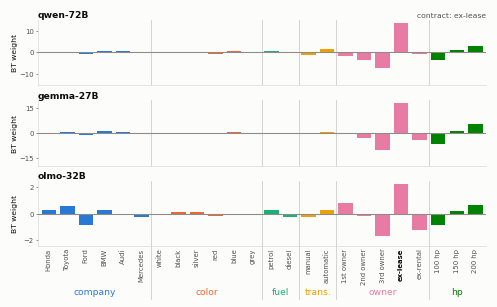

company=BMW+transmission=automatic


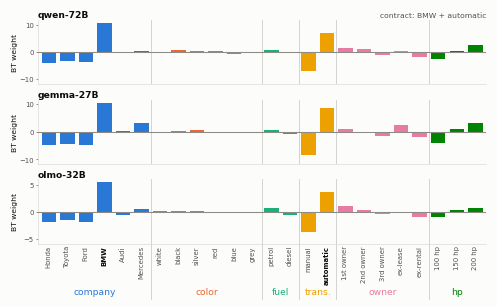

company=BMW+horsepower=200 hp+transmission=automatic


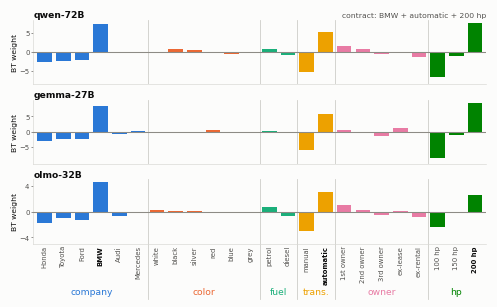

color=black+company=BMW+horsepower=200 hp+transmission=automatic


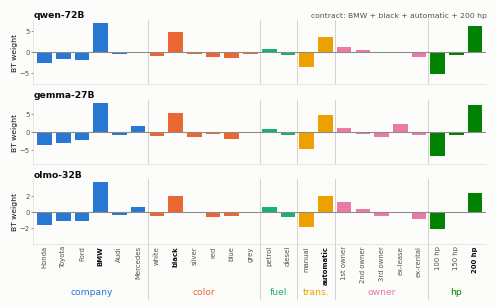

fuel=petrol+transmission=manual


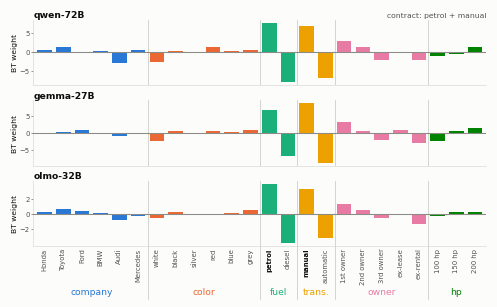

fuel=petrol+horsepower=100 hp+transmission=manual


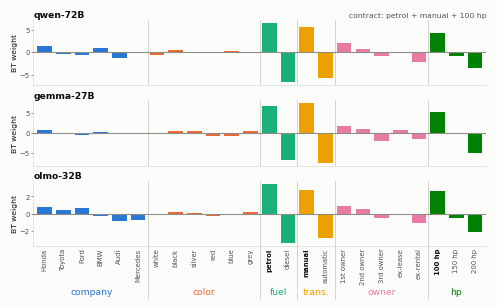

company=Honda+fuel=petrol+horsepower=100 hp+transmission=manual


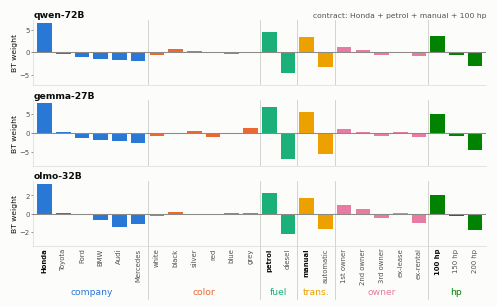

ownership=private first owner+transmission=automatic


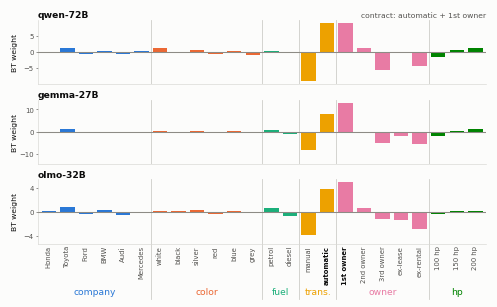

company=Toyota+ownership=private first owner+transmission=automatic


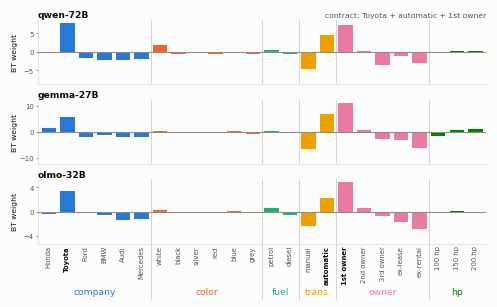

color=white+company=Toyota+ownership=private first owner+transmission=automatic


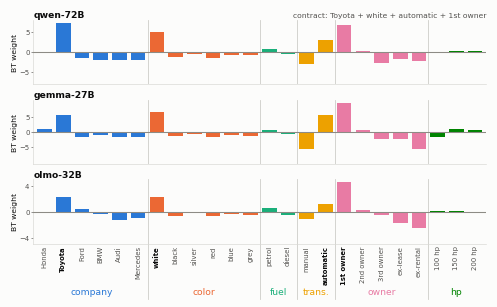

fuel=diesel+horsepower=150 hp


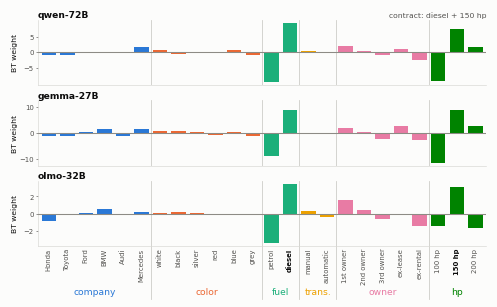

company=Ford+fuel=diesel+horsepower=150 hp


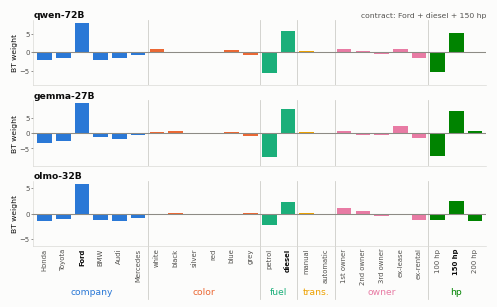

company=Ford+fuel=diesel+horsepower=150 hp+ownership=ex-lease


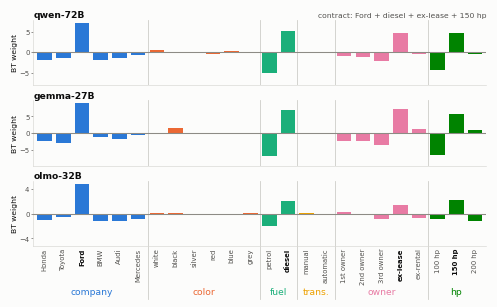

In [6]:
for cid in DS["cars"]["cids"]:
    print(cid)
    fig_weights("cars", cid)

---
# Part 2 — the company weights across a contract sequence

As Fig 6.2 of `figs4deck5_big3` (Apple's decay): one line per company, x = the contracts in order, y = its BT weight
(centred, so 0 = the average company). One panel per model, each with its own y-axis. Every point is fitted on the
**500 shared pairs**, so the only thing that changes along a line is the contract.

One figure per track: none, then the track's four requests added one at a time. Each track asks for a company at one
step (dotted line); that company is drawn bold.

In [7]:
COMPANY_STYLE = dict(zip(DS["cars"]["levels"]["company"],
                         zip(["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"], ["o", "s", "D", "^", "v", "p"])))
TRACKS = {                                                  # as synthetic_cars_trends: requests in the order they are added
    "luxury": [("transmission", "automatic"), ("company", "BMW"), ("horsepower", "200 hp"), ("color", "black")],
    "economy": [("fuel", "petrol"), ("transmission", "manual"), ("horsepower", "100 hp"), ("company", "Honda")],
    "family": [("transmission", "automatic"), ("ownership", "private first owner"), ("company", "Toyota"), ("color", "white")],
    "work": [("fuel", "diesel"), ("horsepower", "150 hp"), ("company", "Ford"), ("ownership", "ex-lease")],
}


def cid_of(con):
    return "+".join(f"{f}={v}" for f, v in sorted(con.items())) or "none"


def company_lines(ds, seq, labels, style, bold=None, asked_at=None, fname="", title=""):
    """One line per company level; every point fitted on the 500 shared pairs. Returns weights and ranks."""
    D = DS[ds]
    feat = D["company"]
    levels = D["levels"][feat]
    fig, axes = plt.subplots(1, 3, figsize=(11.6, 3.7))
    rows = []
    for ax, m in zip(axes, MODELS):
        Wm = pd.DataFrame({c: pd.Series(fit(ds, m, c, shared=True).weights_[feat]) for c in seq}).reindex(levels)
        for l in levels:
            col, mk = style[l]
            ax.plot(range(len(seq)), Wm.loc[l].values, "-", marker=mk, color=col, ms=5,
                    lw=2.4 if l == bold else 1.3, alpha=1.0 if l == bold or bold is None else .75)
        if asked_at is not None:
            ax.axvline(asked_at, color=INK_MUTED, ls=":", lw=1)
            ax.text(asked_at, 1.0, f" {bold} asked", transform=ax.get_xaxis_transform(), fontsize=7.5,
                    color=INK_MUTED, va="top", ha="left")
        ax.axhline(0, color=INK_MUTED, lw=.8)
        ax.set_xticks(range(len(seq)), labels, rotation=30, ha="right", fontsize=8)
        ax.set_title(name(m), loc="left", fontweight="bold", fontsize=10)
        rk = Wm.rank(ascending=False)
        for c, lab in zip(seq, labels):
            rows.append(dict(model=name(m), step=lab, **{l: Wm.loc[l, c] for l in levels},
                             **({f"rank {bold}": int(rk.loc[bold, c])} if bold else {})))
    axes[0].set_ylabel(f"{feat} weight (log-odds)")
    fig.legend(handles=[Line2D([], [], marker=style[l][1], color=style[l][0], label=l) for l in levels],
               ncol=len(levels), loc="lower center", frameon=False, bbox_to_anchor=(.5, -.02))
    if title:
        fig.suptitle(title, x=.01, ha="left", fontweight="bold", fontsize=10)
    fig.tight_layout(rect=[0, .09, 1, 1])
    save(fig, "company_lines", fname)
    plt.show()
    return pd.DataFrame(rows)

## Company weights along each track

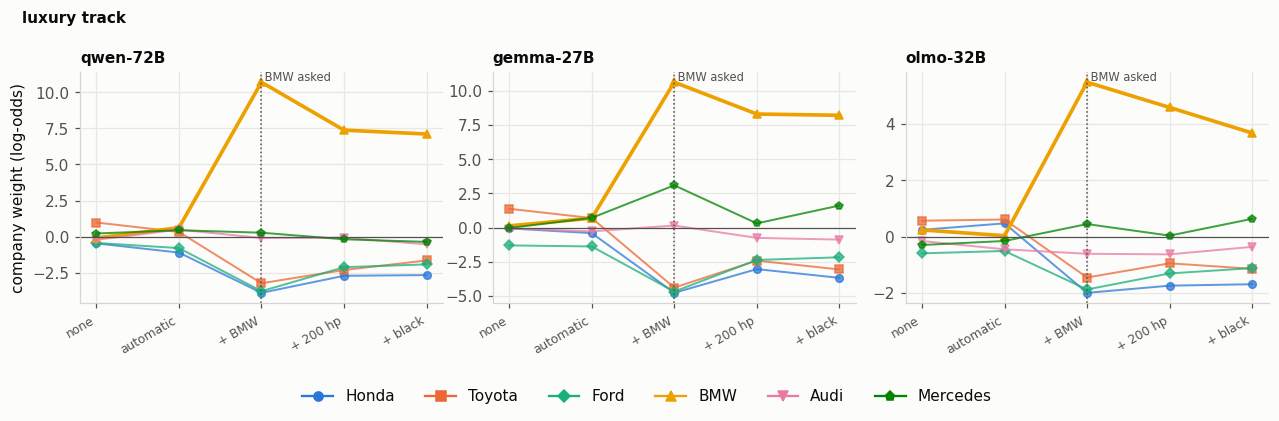

luxury: company weights (log-odds), 500 shared pairs
                     Honda  Toyota  Ford    BMW  Audi  Mercedes  rank BMW
model     step                                                           
qwen-72B  none       -0.46    0.98 -0.43  -0.09 -0.21      0.22         3
          automatic  -1.10    0.33 -0.79   0.62  0.49      0.45         1
          + BMW      -3.89   -3.23 -3.77  10.70 -0.09      0.28         1
          + 200 hp   -2.71   -2.31 -2.11   7.38 -0.07     -0.18         1
          + black    -2.66   -1.65 -1.92   7.11 -0.53     -0.36         1
gemma-27B none       -0.07    1.37 -1.31   0.12 -0.08     -0.04         2
          automatic  -0.41    0.69 -1.39   0.68 -0.28      0.71         3
          + BMW      -4.78   -4.40 -4.68  10.63  0.14      3.09         1
          + 200 hp   -3.04   -2.42 -2.37   8.30 -0.76      0.30         1
          + black    -3.68   -3.07 -2.18   8.21 -0.88      1.61         1
olmo-32B  none        0.24    0.56 -0.59   0.24 -0.16     -

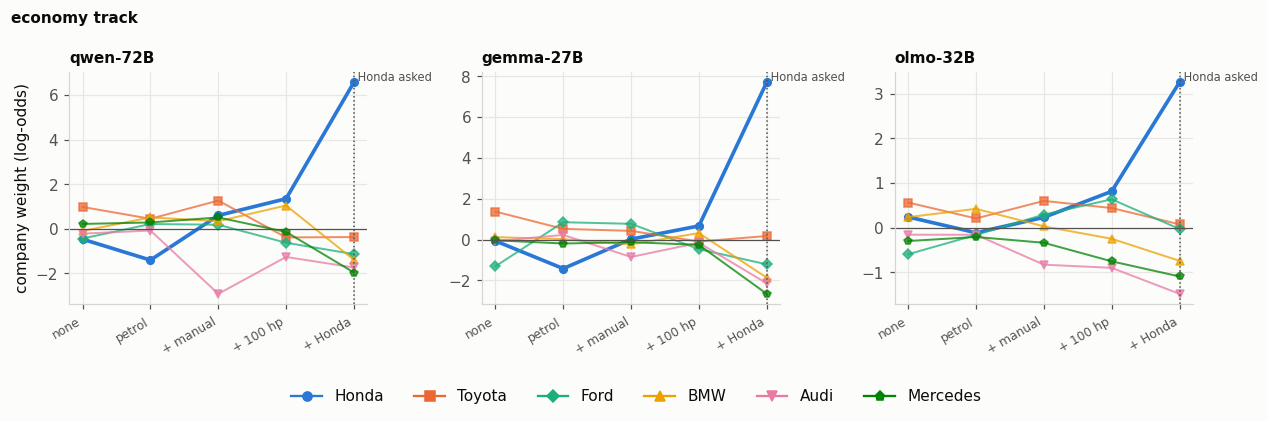

economy: company weights (log-odds), 500 shared pairs
                    Honda  Toyota  Ford   BMW  Audi  Mercedes  rank Honda
model     step                                                           
qwen-72B  none      -0.46    0.98 -0.43 -0.09 -0.21      0.22           6
          petrol    -1.40    0.45  0.22  0.51 -0.07      0.29           6
          + manual   0.60    1.27  0.19  0.34 -2.91      0.51           2
          + 100 hp   1.35   -0.38 -0.62  1.05 -1.26     -0.14           1
          + Honda    6.57   -0.37 -1.13 -1.39 -1.73     -1.96           1
gemma-27B none      -0.07    1.37 -1.31  0.12 -0.08     -0.04           4
          petrol    -1.42    0.52  0.85  0.02  0.23     -0.19           6
          + manual   0.02    0.43  0.77 -0.24 -0.85     -0.13           3
          + 100 hp   0.67   -0.10 -0.47  0.32 -0.16     -0.26           1
          + Honda    7.71    0.17 -1.21 -1.86 -2.14     -2.66           1
olmo-32B  none       0.24    0.56 -0.59  0.24 -0.16     -0

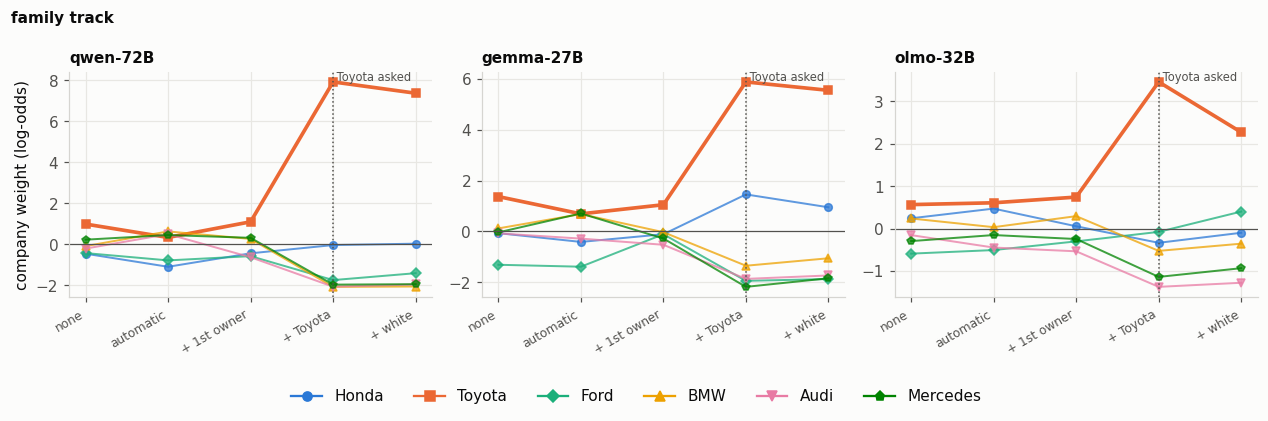

family: company weights (log-odds), 500 shared pairs
                       Honda  Toyota  Ford   BMW  Audi  Mercedes  rank Toyota
model     step                                                               
qwen-72B  none         -0.46    0.98 -0.43 -0.09 -0.21      0.22            1
          automatic    -1.10    0.33 -0.79  0.62  0.49      0.45            4
          + 1st owner  -0.44    1.09 -0.58  0.26 -0.63      0.31            1
          + Toyota     -0.04    7.92 -1.75 -2.08 -2.07     -1.97            1
          + white       0.03    7.37 -1.41 -2.06 -1.97     -1.95            1
gemma-27B none         -0.07    1.37 -1.31  0.12 -0.08     -0.04            1
          automatic    -0.41    0.69 -1.39  0.68 -0.28      0.71            2
          + 1st owner  -0.11    1.05 -0.11 -0.03 -0.52     -0.28            1
          + Toyota      1.45    5.88 -1.94 -1.35 -1.86     -2.18            1
          + white       0.95    5.54 -1.87 -1.05 -1.73     -1.84            1
olmo-32B  n

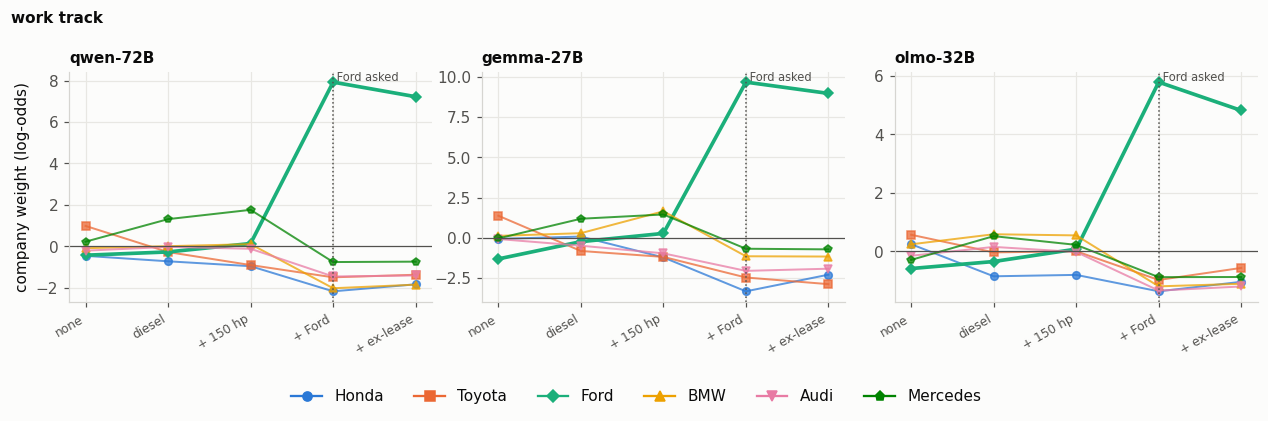

work: company weights (log-odds), 500 shared pairs
                      Honda  Toyota  Ford   BMW  Audi  Mercedes  rank Ford
model     step                                                            
qwen-72B  none        -0.46    0.98 -0.43 -0.09 -0.21      0.22          5
          diesel      -0.73   -0.28 -0.27  0.00 -0.03      1.31          4
          + 150 hp    -0.96   -0.91  0.13  0.10 -0.12      1.76          2
          + Ford      -2.18   -1.50  7.93 -2.03 -1.46     -0.76          1
          + ex-lease  -1.84   -1.38  7.22 -1.85 -1.41     -0.74          1
gemma-27B none        -0.07    1.37 -1.31  0.12 -0.08     -0.04          6
          diesel       0.08   -0.82 -0.24  0.29 -0.49      1.18          4
          + 150 hp    -1.22   -1.18  0.27  1.64 -0.96      1.45          3
          + Ford      -3.32   -2.46  9.66 -1.15 -2.05     -0.68          1
          + ex-lease  -2.29   -2.87  8.96 -1.16 -1.92     -0.72          1
olmo-32B  none         0.24    0.56 -0.59  0.24 -

In [8]:
CAR_LINES = []
for tr, reqs in TRACKS.items():
    seq = [cid_of(dict(reqs[:k])) for k in range(len(reqs) + 1)]
    labels = ["none"] + [("" if k == 0 else "+ ") + OWN.get(v, v) for k, (f, v) in enumerate(reqs)]
    k_co = [k for k, (f, _) in enumerate(reqs) if f == "company"][0] + 1          # step where the company is asked
    company = reqs[k_co - 1][1]
    t = company_lines("cars", seq, labels, COMPANY_STYLE, bold=company, asked_at=k_co, fname=f"cars_company_{tr}",
                      title=f"{tr} track")
    CAR_LINES.append(t.assign(track=tr))
    print(f"{tr}: company weights (log-odds), 500 shared pairs")
    print(t.set_index(["model", "step"]).round(2).to_string(), "\n")

---
# Part 3 — adherence: Δp on the conflict pairs, every contract

For each contract and model:

1. **The model's own preference** comes from its **no-contract run**: for every pair, the position-corrected margin
   $D_0 = \tfrac12[m(x,y) - m(y,x)]$.
2. **The pairs:** exactly one of the two items meets the contract (every asked level). A pair is a **conflict** pair
   when the item that meets it loses with no contract ($D_0 < 0$): obeying costs the model something it wants.
3. **Δp** = mean over the conflict prompts of $P(\text{item that meets the contract}) - P(\text{other item})$, under
   the contract, with the two answer probabilities normalised to sum to 1 (per prompt $\tanh(m/2)$), both slot
   orders. +1 = always picks what was asked, 0 = coin flip (dashed), −1 = always picks its own preference.

Bar colour = how many requests the contract has. The table adds the number of conflict pairs, the position-corrected
win rate, $g_0 \to g_1$ and $\kappa$.

In [9]:
DEPTH_COLOR = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a", 4: "#4a3aa7"}


def margins(ds, d):
    """M[x, y] = score_a - score_b of the prompt with x in slot A (NaN = not asked)."""
    D = DS[ds]
    n = len(D["ids"])
    M = np.full((n, n), np.nan)
    M[d.a_id.map(D["pos"]).values, d.b_id.map(D["pos"]).values] = (d.score_a - d.score_b).values
    return M


def adherence(ds):
    D, rows = DS[ds], []
    lvl = D["items"][D["feats"]]
    for m in MODELS:
        M0 = margins(ds, RUNS[ds][(m, "none")])
        D0 = (M0 - M0.T) / 2
        for cid in D["cids"][1:]:
            con = parse(cid)
            meets = np.array([all(lvl.loc[i, f] == v for f, v in con.items()) for i in D["ids"]])
            M1 = margins(ds, RUNS[ds][(m, cid)])
            D1 = (M1 - M1.T) / 2
            s, o = np.where(meets)[0], np.where(~meets)[0]
            S, O = np.meshgrid(s, o, indexing="ij")
            S, O = S.ravel(), O.ravel()
            asked = np.isfinite(M1[S, O]) & np.isfinite(M1[O, S])            # pair in the contract run, both orders
            S, O = S[asked], O[asked]
            conf = D0[S, O] < 0
            Sc, Oc = S[conf], O[conf]
            dp = np.r_[np.tanh(M1[Sc, Oc] / 2), np.tanh(-M1[Oc, Sc] / 2)]   # both slot orders
            g0, g1 = D0[Sc, Oc].mean() if conf.any() else np.nan, D1[Sc, Oc].mean() if conf.any() else np.nan
            rows.append(dict(model=name(m), family=m[0], contract=cid, depth=len(con), pairs=len(S),
                             n_conflict=int(conf.sum()), dp=dp.mean() if conf.any() else np.nan,
                             win=100 * (D1[Sc, Oc] > 0).mean() if conf.any() else np.nan,
                             g0=g0, g1=g1, kappa=1 - g1 / g0 if conf.any() else np.nan))
    return pd.DataFrame(rows)


def fig_adherence(ds, A):
    D = DS[ds]
    cids = D["cids"][1:]
    yy = np.arange(len(cids))[::-1]
    fig, axes = plt.subplots(1, 3, figsize=(11.6, 0.27 * len(cids) + 1.2), sharey=True)
    for ax, m in zip(axes, MODELS):
        t = A[A.model == name(m)].set_index("contract").reindex(cids)
        ax.barh(yy, t.dp, .62, color=[DEPTH_COLOR[k] for k in t.depth], zorder=3)
        ax.axvline(0, color=INK_MUTED, ls="--", lw=1)
        for y, v in zip(yy, t.dp):
            if np.isfinite(v):
                ax.text(v + (.03 if v >= 0 else -.03), y, f"{v:.2f}", va="center", ha="left" if v >= 0 else "right",
                        fontsize=7, fontweight="bold", color=INK, zorder=6)
        ax.set_xlim(-1.08, 1.32)
        ax.set_xticks([-1, -.5, 0, .5, 1])
        ax.set_xlabel("Δp")
        ax.set_title(m[0], loc="left", fontweight="bold", fontsize=10)
        ax.grid(axis="y", visible=False)
    axes[0].set_yticks(yy, [short(ds, c) for c in cids], fontsize=7.5)
    axes[0].set_ylim(-.7, len(cids) - .3)
    depths = sorted(A.depth.unique())
    fig.legend(handles=[Rectangle((0, 0), 1, 1, color=DEPTH_COLOR[k]) for k in depths],
               labels=[f"{k} request{'s' if k > 1 else ''}" for k in depths],
               loc="upper right", ncol=len(depths), frameon=False, fontsize=8.5, bbox_to_anchor=(.995, 1.0))
    fig.suptitle(D["title"], x=.01, y=1.0, ha="left", fontweight="bold", fontsize=10, va="top")
    fig.tight_layout(rect=[0, 0, 1, .97])
    save(fig, "adherence", f"adherence_{ds}")
    plt.show()

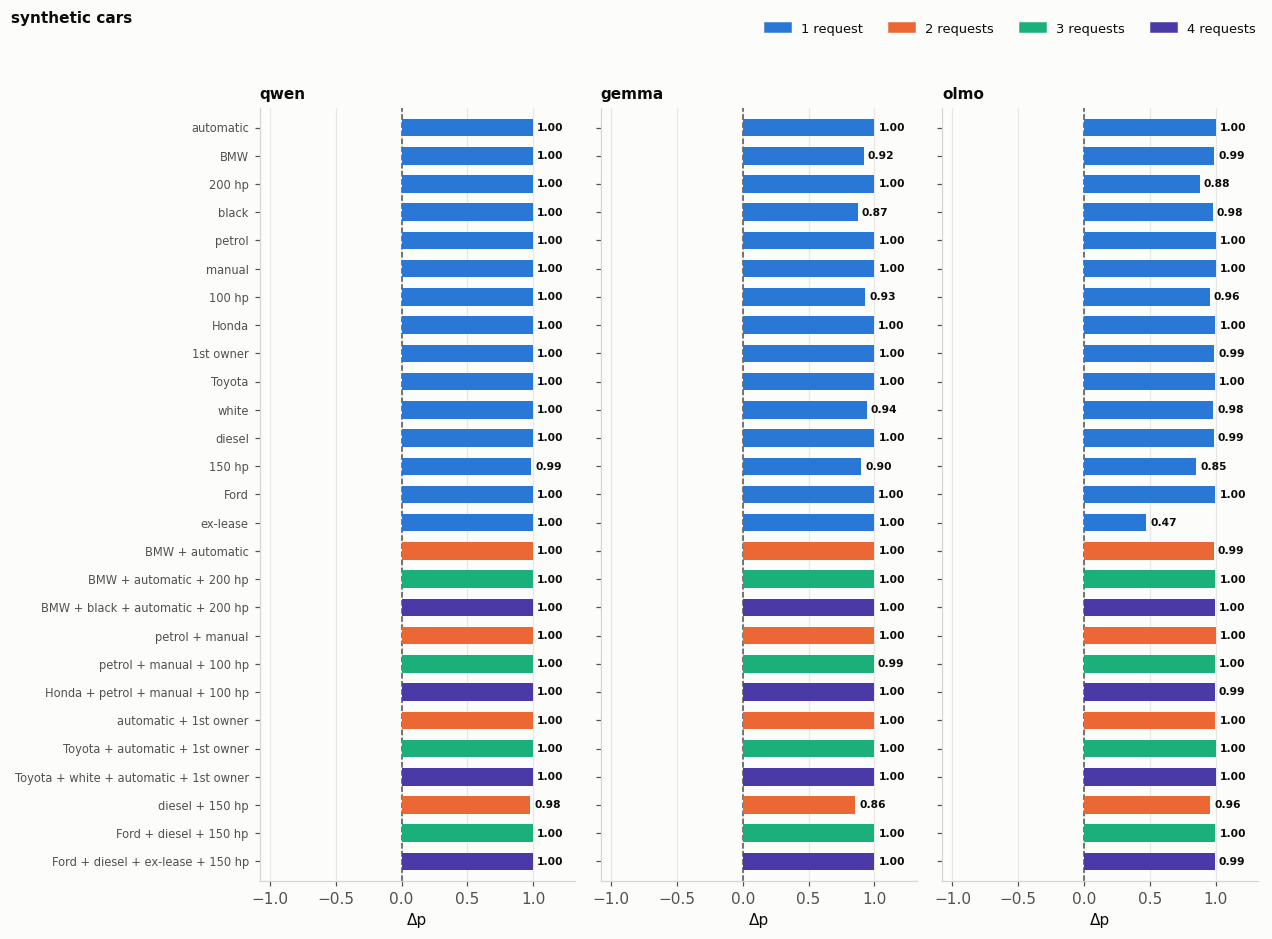

                                                                                           pairs  n_conflict    dp     win     g0     g1  kappa
model     contract                                                                                                                             
qwen-72B  transmission=automatic                                                            3600        1525  1.00  100.00  -6.57  22.30   4.39
          company=BMW                                                                       2000         945  1.00  100.00  -9.40  16.74   2.78
          horsepower=200 hp                                                                 3200         251  1.00  100.00  -3.04  19.66   7.46
          color=black                                                                       2000         986  1.00  100.00  -8.26  16.99   3.06
          fuel=petrol                                                                       3600        1626  1.00  100.00  -7.61  23.31

In [10]:
AD_C = adherence("cars")
AD_C.to_csv(os.path.join(FIGDIR, "adherence_cars.csv"), index=False)
fig_adherence("cars", AD_C)
print(AD_C.set_index(["model", "contract"])[["pairs", "n_conflict", "dp", "win", "g0", "g1", "kappa"]].round(2).to_string())